# CS 463 Project Update 2 — M5 Retail Demand EDA

## Project Goal

The goal of this EDA is to understand the main patterns and quality of the retail data before building forecasting models. We will examine sales trends, differences between products and stores, calendar and event effects, pricing patterns, missing values, and zero-sales periods.


## How These CSV Files Support Retail Demand Forecasting

- `sales_train_validation.csv` — provides the historical product sales that our model will use to learn demand patterns.
- `calendar.csv` — adds time-related information such as weekdays, holidays, and events that may influence future sales.
- `sell_prices.csv` — adds product pricing information so we can study whether price changes are associated with changes in demand.

Together, these files provide the main information needed to forecast future retail product demand.


In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

calendar = pd.read_csv("calendar.csv")
sales = pd.read_csv("sales_train_validation.csv")
prices = pd.read_csv("sell_prices.csv")


## 1. Dataset Overview


In [2]:
print("Calendar shape:", calendar.shape)
print("Sales shape:", sales.shape)
print("Prices shape:", prices.shape)


Calendar shape: (1969, 14)
Sales shape: (30490, 1919)
Prices shape: (6841121, 4)


In [3]:
calendar.head()


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [4]:
sales.head()


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [5]:
prices.head()


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [6]:
calendar.info()


<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          1969 non-null   str  
 1   wm_yr_wk      1969 non-null   int64
 2   weekday       1969 non-null   str  
 3   wday          1969 non-null   int64
 4   month         1969 non-null   int64
 5   year          1969 non-null   int64
 6   d             1969 non-null   str  
 7   event_name_1  162 non-null    str  
 8   event_type_1  162 non-null    str  
 9   event_name_2  5 non-null      str  
 10  event_type_2  5 non-null      str  
 11  snap_CA       1969 non-null   int64
 12  snap_TX       1969 non-null   int64
 13  snap_WI       1969 non-null   int64
dtypes: int64(7), str(7)
memory usage: 215.5 KB


In [7]:
sales.info()


<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), str(6)
memory usage: 446.4 MB


In [8]:
prices.info()


<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 208.8 MB


## 2. Missing Values


In [9]:
print("Calendar missing values:")
print(calendar.isnull().sum())


Calendar missing values:
date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64


In [10]:
print("Total missing values in sales:", sales.isnull().sum().sum())


Total missing values in sales: 0


In [11]:
print("Price missing values:")
print(prices.isnull().sum())


Price missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64


**Note:** Missing values in event columns are expected because most dates do not have a special event or holiday.


## 3. Sales Dataset Structure


In [12]:
print("Products:", sales["item_id"].nunique())
print("Departments:", sales["dept_id"].nunique())
print("Categories:", sales["cat_id"].nunique())
print("Stores:", sales["store_id"].nunique())
print("States:", sales["state_id"].nunique())


Products: 3049
Departments: 7
Categories: 3
Stores: 10
States: 3


In [13]:
sales["cat_id"].value_counts()


cat_id
FOODS        14370
HOUSEHOLD    10470
HOBBIES       5650
Name: count, dtype: int64

## 4. Zero-Sales Analysis


In [14]:
day_cols = [col for col in sales.columns if col.startswith("d_")]

zero_count = (sales[day_cols] == 0).sum().sum()
total_values = sales[day_cols].size
zero_percentage = zero_count / total_values * 100

print("Percentage of zero-sales observations:", zero_percentage)


Percentage of zero-sales observations: 68.19627560783213


## 5. Total Sales Over Time


In [15]:
daily_sales = sales[day_cols].sum().reset_index()
daily_sales.columns = ["d", "total_sales"]

daily_sales = daily_sales.merge(
    calendar[["d", "date", "weekday", "event_name_1"]],
    on="d",
    how="left"
)

daily_sales["date"] = pd.to_datetime(daily_sales["date"])

daily_sales.head()


,d,total_sales,date,weekday,event_name_1
0,d_1,32631,2011-01-29,Saturday,NaN
1,d_2,31749,2011-01-30,Sunday,NaN
2,d_3,23783,2011-01-31,Monday,NaN
3,d_4,25412,2011-02-01,Tuesday,NaN
4,d_5,19146,2011-02-02,Wednesday,NaN


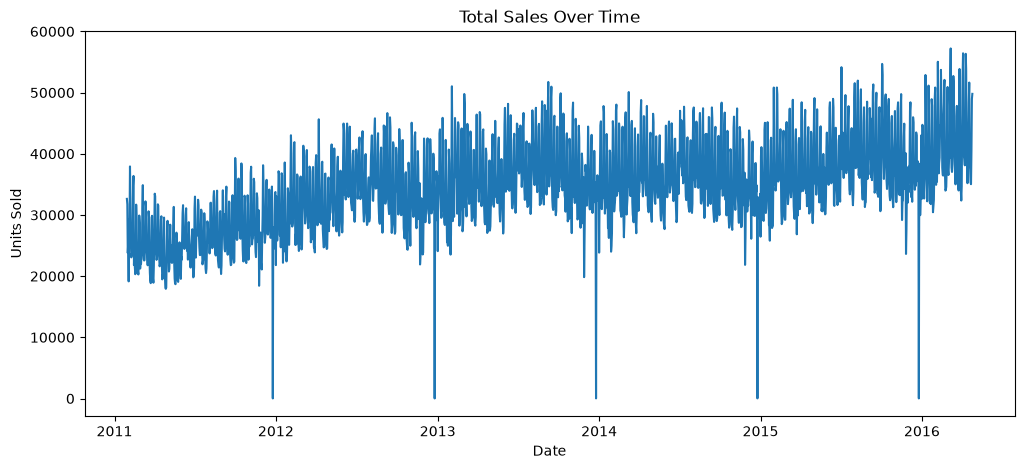

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(daily_sales["date"], daily_sales["total_sales"])
plt.title("Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.show()


## 6. Sales by Product Category


In [17]:
category_sales = (
    sales.groupby("cat_id")[day_cols]
    .sum()
    .sum(axis=1)
)

category_sales


cat_id
FOODS        45089939
HOBBIES       6124800
HOUSEHOLD    14480670
dtype: int64

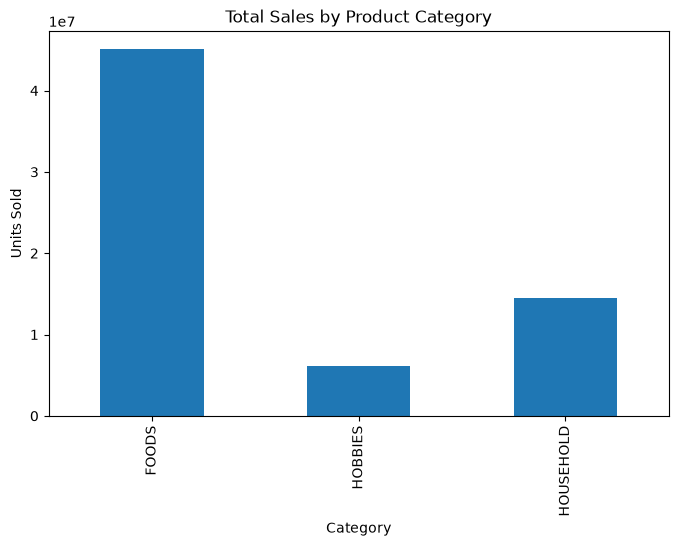

In [18]:
category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.show()


## 7. Sales by State


In [19]:
state_sales = (
    sales.groupby("state_id")[day_cols]
    .sum()
    .sum(axis=1)
)

state_sales


state_id
CA    28675547
TX    18899006
WI    18120856
dtype: int64

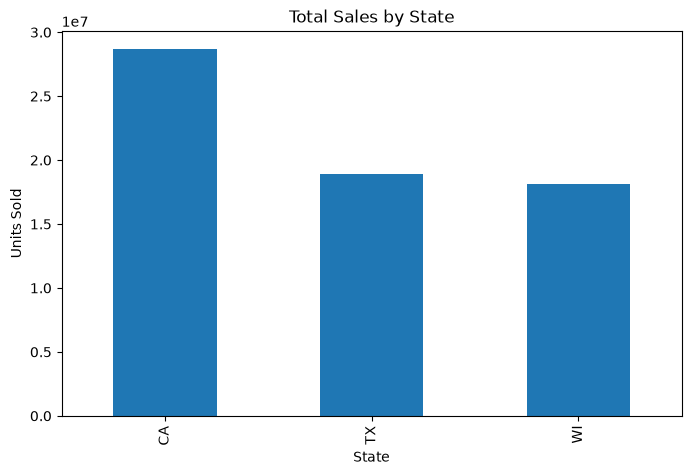

In [20]:
state_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Units Sold")
plt.show()


## 8. Average Sales by Weekday


In [21]:
weekday_sales = daily_sales.groupby("weekday")["total_sales"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

weekday_sales


weekday
Monday       32852.967033
Tuesday      30368.780220
Wednesday    30010.021978
Thursday     30205.007326
Friday       34225.985348
Saturday     41546.894161
Sunday       41130.021898
Name: total_sales, dtype: float64

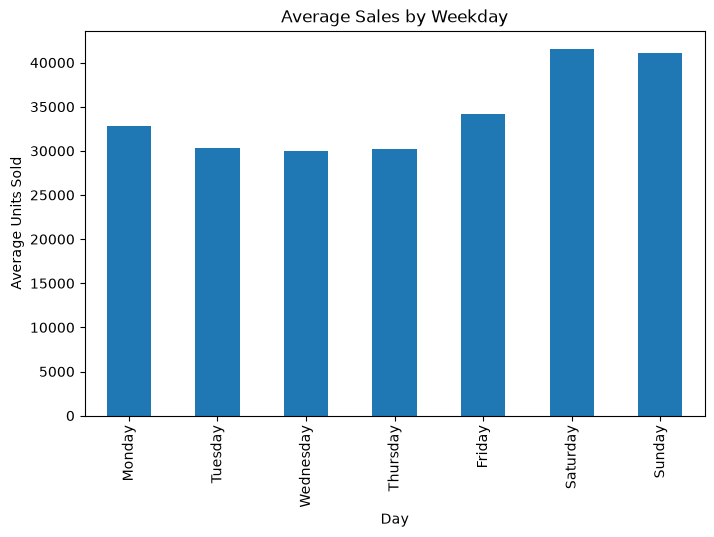

In [22]:
weekday_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales by Weekday")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")
plt.show()


## 9. Event Days vs Normal Days


In [23]:
daily_sales["is_event"] = daily_sales["event_name_1"].notna()

event_sales = daily_sales.groupby("is_event")["total_sales"].mean()
event_sales


is_event
False    34489.207504
True     32655.149351
Name: total_sales, dtype: float64

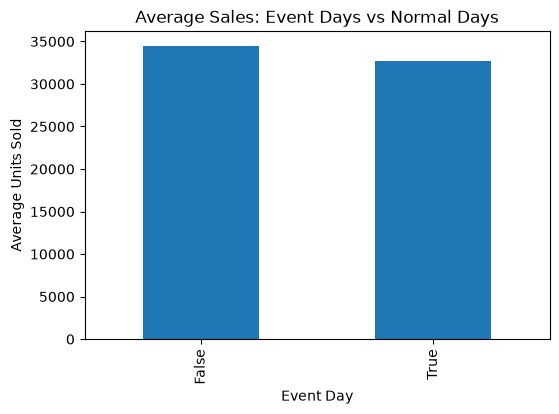

In [24]:
event_sales.plot(kind="bar", figsize=(6, 4))
plt.title("Average Sales: Event Days vs Normal Days")
plt.xlabel("Event Day")
plt.ylabel("Average Units Sold")
plt.show()


## Holiday and Event Analysis

We treat missing holiday/event values as **No Event** because most dates do not have a named event. This section explores how individual holidays and event types relate to total sales.


In [25]:
event_columns = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]

for col in event_columns:
    calendar[col] = calendar[col].fillna("No Event")


In [26]:
calendar["event_name_1"].value_counts()


event_name_1
No Event               1807
SuperBowl                 6
ValentinesDay             6
PresidentsDay             6
LentStart                 6
LentWeek2                 6
StPatricksDay             6
Purim End                 6
Pesach End                6
Mother's day              6
MemorialDay               6
NBAFinalsStart            6
NBAFinalsEnd              6
Ramadan starts            6
OrthodoxEaster            5
Cinco De Mayo             5
IndependenceDay           5
Eid al-Fitr               5
LaborDay                  5
ColumbusDay               5
Halloween                 5
EidAlAdha                 5
VeteransDay               5
Thanksgiving              5
Christmas                 5
Chanukah End              5
NewYear                   5
OrthodoxChristmas         5
MartinLutherKingDay       5
Easter                    5
Father's day              4
Name: count, dtype: int64

In [27]:
calendar["event_type_1"].value_counts()


event_type_1
No Event     1807
Religious      55
National       52
Cultural       37
Sporting       18
Name: count, dtype: int64

In [28]:
holiday_sales_df = daily_sales[["d", "date", "total_sales"]].merge(
    calendar[
        [
            "d",
            "event_name_1",
            "event_type_1",
            "event_name_2",
            "event_type_2"
        ]
    ],
    on="d",
    how="left"
)

holiday_sales_df.head()


,d,date,total_sales,event_name_1,event_type_1,event_name_2,event_type_2
0,d_1,2011-01-29,32631,No Event,No Event,No Event,No Event
1,d_2,2011-01-30,31749,No Event,No Event,No Event,No Event
2,d_3,2011-01-31,23783,No Event,No Event,No Event,No Event
3,d_4,2011-02-01,25412,No Event,No Event,No Event,No Event
4,d_5,2011-02-02,19146,No Event,No Event,No Event,No Event


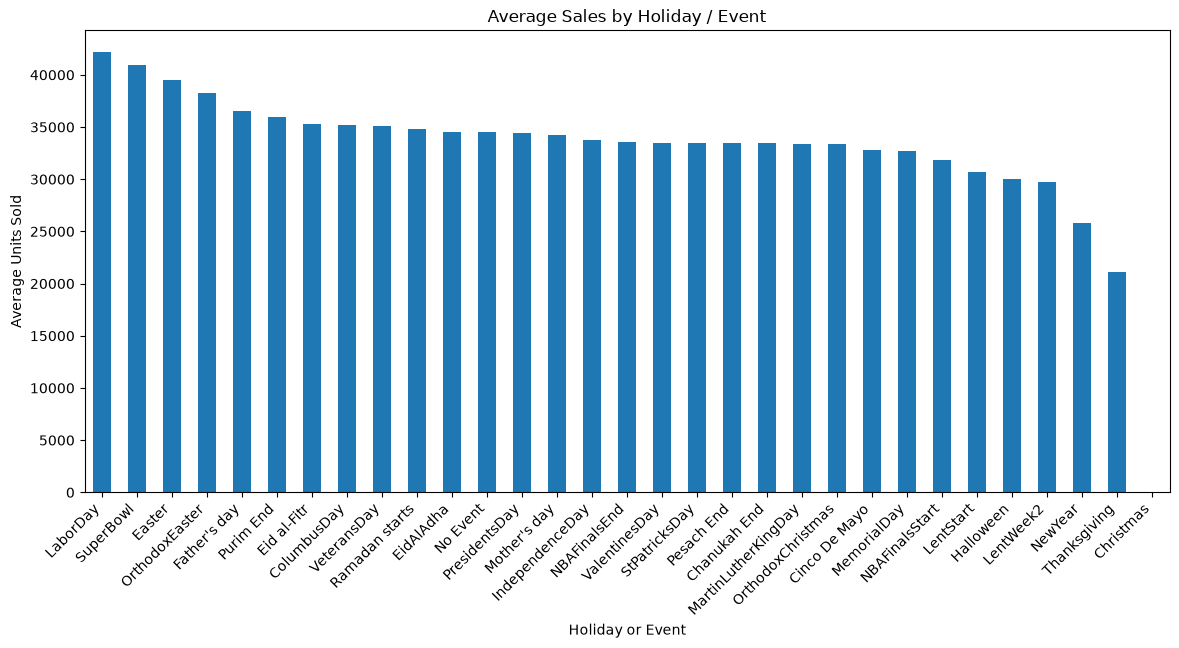

In [29]:
event_name_sales = (
    holiday_sales_df
    .groupby("event_name_1")["total_sales"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
event_name_sales.plot(kind="bar")

plt.title("Average Sales by Holiday / Event")
plt.xlabel("Holiday or Event")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45, ha="right")
plt.show()


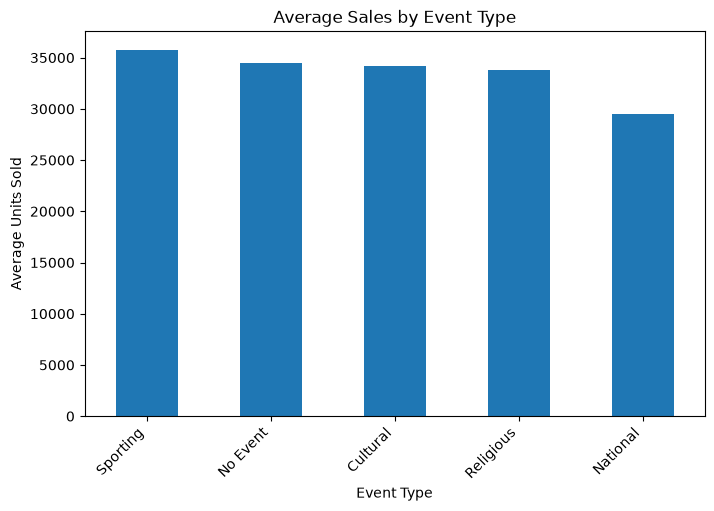

In [30]:
event_type_sales = (
    holiday_sales_df
    .groupby("event_type_1")["total_sales"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
event_type_sales.plot(kind="bar")

plt.title("Average Sales by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45, ha="right")
plt.show()


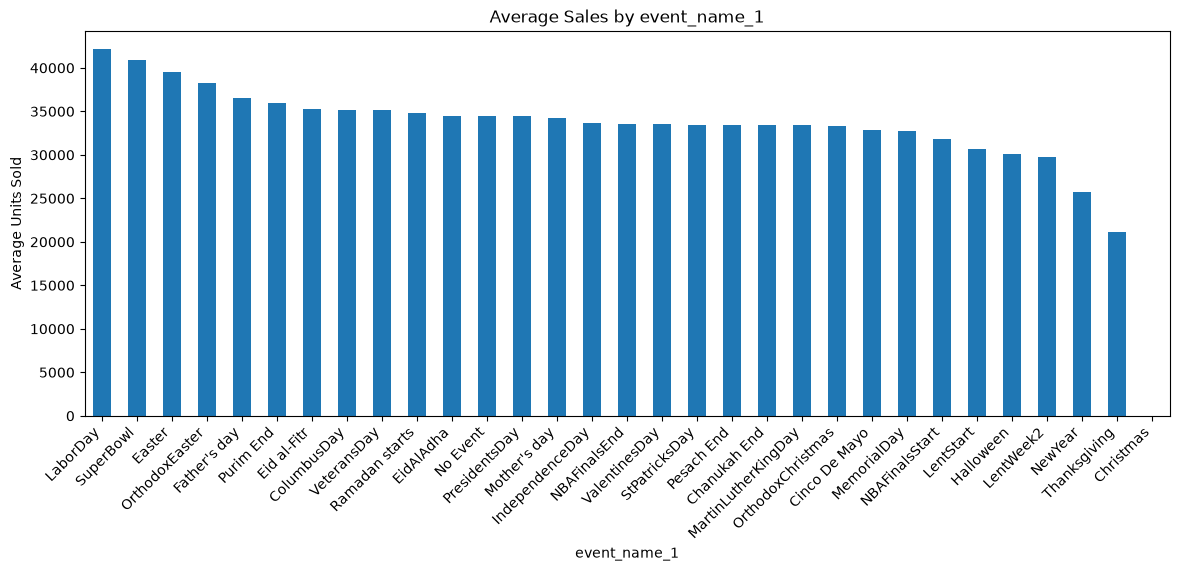

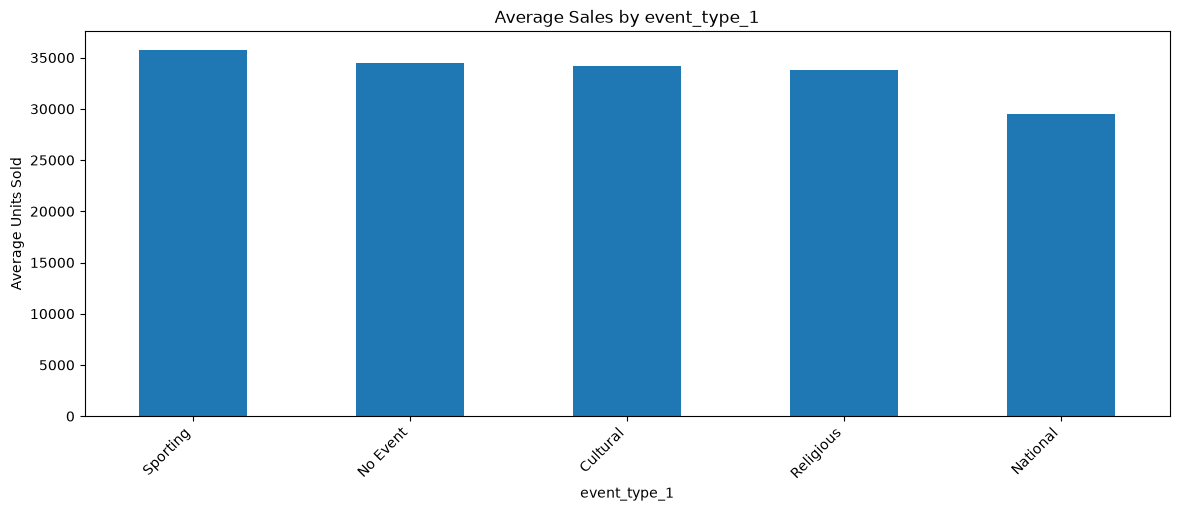

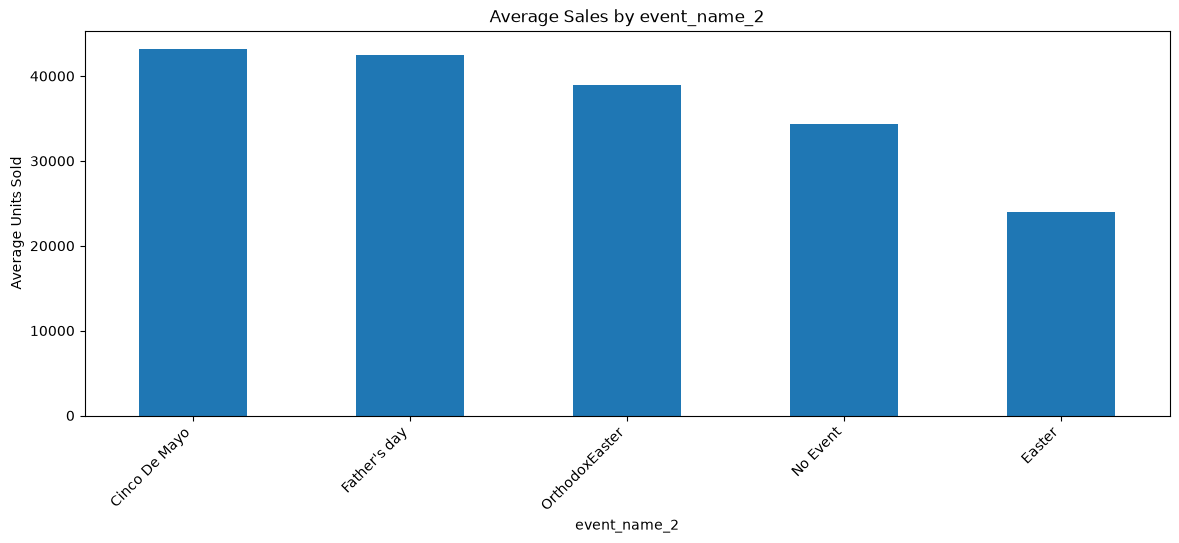

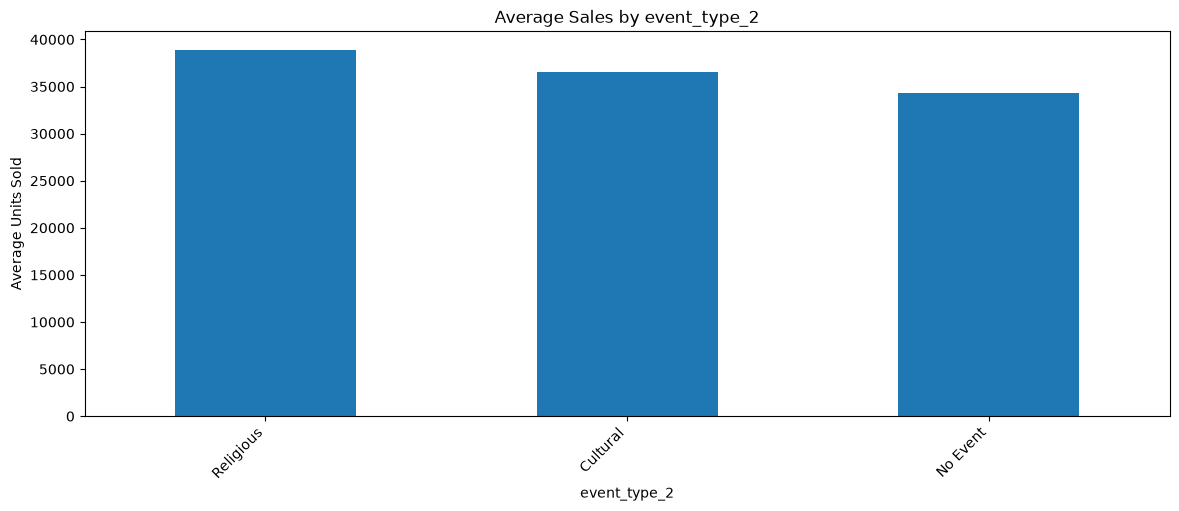

In [31]:
for col in event_columns:
    sales_by_event = (
        holiday_sales_df
        .groupby(col)["total_sales"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(14, 5))
    sales_by_event.plot(kind="bar")

    plt.title(f"Average Sales by {col}")
    plt.xlabel(col)
    plt.ylabel("Average Units Sold")
    plt.xticks(rotation=45, ha="right")
    plt.show()


## 10. Price Analysis


In [32]:
prices["sell_price"].describe()


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

In [34]:
price_variation = (
    prices.groupby(["store_id", "item_id"])["sell_price"]
    .nunique()
    .describe()
)

price_variation


count    30490.000000
mean         2.769367
std          1.893627
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         21.000000
Name: sell_price, dtype: float64

In [46]:
sales_sample = sales[sales["store_id"] == "CA_1"]

sales_long = sales_sample.melt(
    id_vars=[
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_cols,
    var_name="d",
    value_name="sales"
)

merged_data = sales_long.merge(
    calendar[
        [
            "d",
            "date",
            "wm_yr_wk",
            "wday",
            "month",
            "snap_CA"
        ]
    ],
    on="d",
    how="left"
)

merged_data = merged_data.merge(
    prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

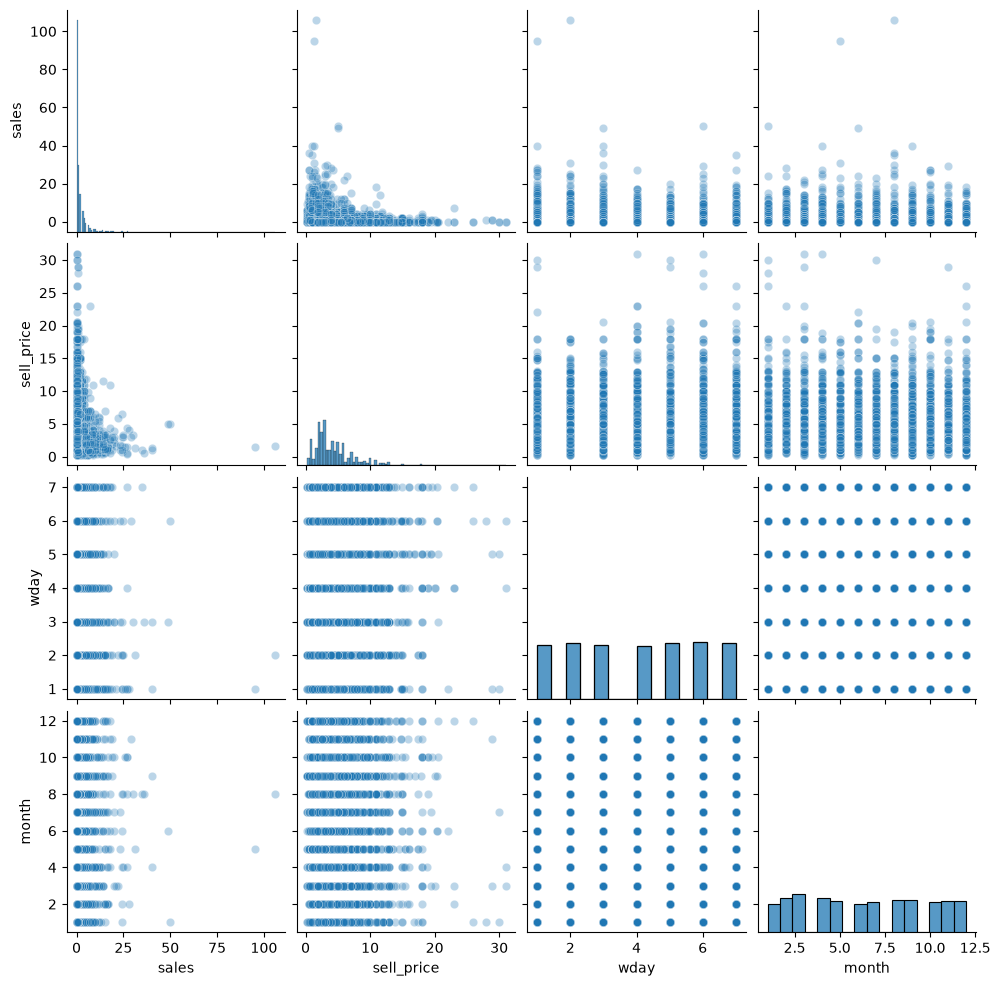

In [47]:
pairplot_data = merged_data[
    ["sales", "sell_price", "wday", "month"]
].dropna()

pairplot_data = pairplot_data.sample(
    min(5000, len(pairplot_data)),
    random_state=42
)

sns.pairplot(
    pairplot_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.3}
)

plt.show()

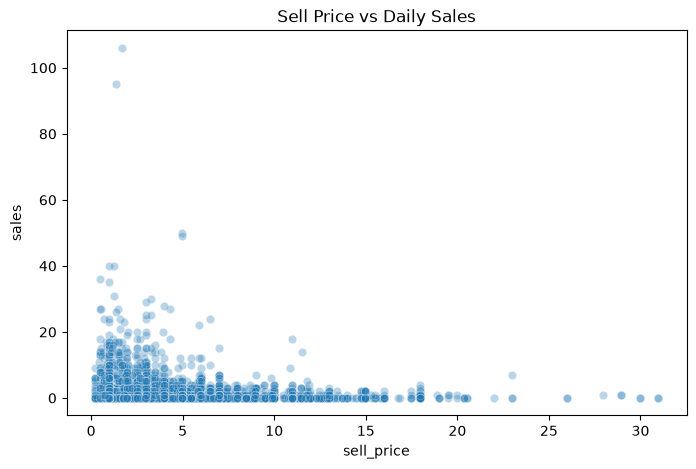

In [48]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=pairplot_data,
    x="sell_price",
    y="sales",
    alpha=0.3
)

plt.title("Sell Price vs Daily Sales")
plt.show()

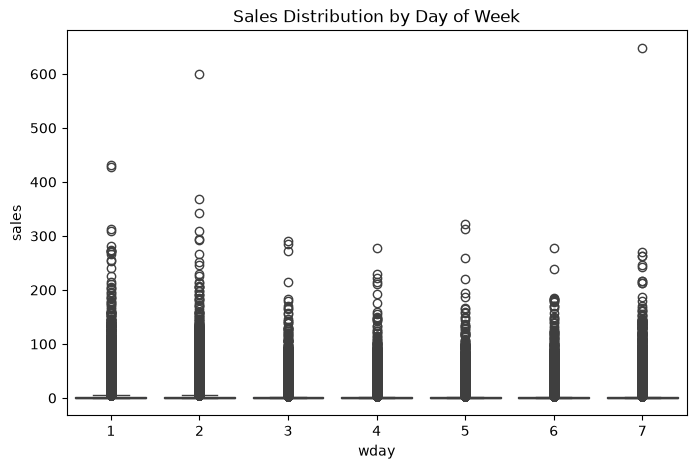

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=merged_data,
    x="wday",
    y="sales"
)

plt.title("Sales Distribution by Day of Week")
plt.show()

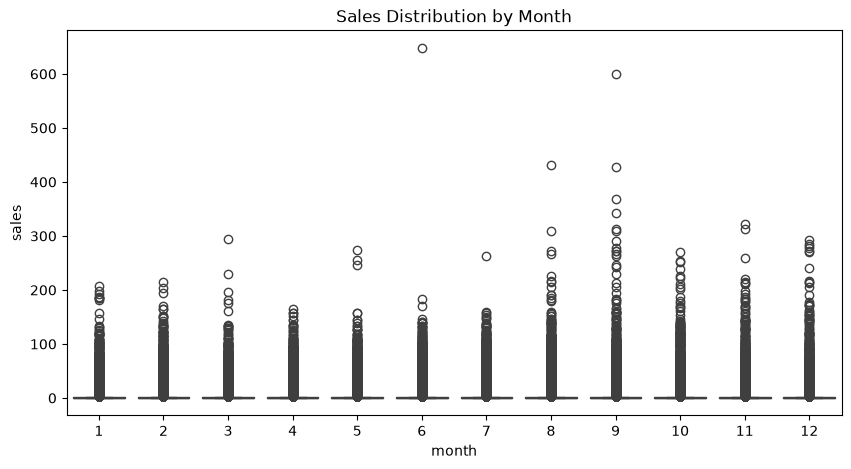

In [50]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=merged_data,
    x="month",
    y="sales"
)

plt.title("Sales Distribution by Month")
plt.show()

## 11. Key Takeaways and Future Features

This EDA helped me better understand the structure, quality, and behavior of the M5 retail dataset before building forecasting models.

I explored:

- **Sales over time** to look for long-term trends, seasonality, spikes, and repeating demand patterns.
- **Differences between product categories** to see whether food, household, and hobby products have different demand behavior.
- **Differences between states** to identify whether sales patterns vary across California, Texas, and Wisconsin.
- **Weekday patterns** to determine whether demand changes depending on the day of the week.
- **Holiday and event effects** to compare normal days with special events and examine whether certain events are associated with changes in sales. One notable finding was that **Christmas had extremely low recorded sales compared with other events**, making it a clear outlier in the holiday analysis.
- **Zero-sales periods** to understand how often products have no recorded sales and whether some products have intermittent demand.
- **Product pricing** to examine how prices vary across products and over time.

### Data Quality

I also checked for missing values across the datasets.

- Missing values in the holiday and event columns were expected because most dates do not contain a special event. I treated these values as **"No Event"** rather than as data errors.
- I also checked the sales and pricing datasets for missing values to determine whether additional cleaning may be required before modeling.

I also looked for possible **outliers**, such as unusually large sales values or unusually high or low product prices. Some extreme values may represent real demand spikes, holidays, promotions, or expensive products rather than incorrect data, so these values should be investigated before deciding whether to remove or transform them.

Based on the EDA, possible future forecasting features include:

- `sales_lag_1` — sales from the previous day
- `sales_lag_7` — sales from one week earlier
- `sales_lag_28` — sales from four weeks earlier
- `rolling_mean_7` — average sales over the previous 7 days
- `rolling_mean_28` — average sales over the previous 28 days
- `day_of_week`
- `is_weekend`
- `is_event_day`
- `event_type`
- `sell_price`
- `price_change`

These features can later be used to test which types of information are most useful for predicting future retail demand.

Because this is a forecasting problem, I should preserve chronological order rather than randomly splitting observations into training and testing sets. This helps ensure that the models are evaluated on future data that was not available during training.